# Exploratory Data Analysis (EDA) - Bivariate 

## Loading and preparing the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
from scipy.stats import pearsonr
from scipy.stats import probplot

In [2]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
# Removing the "UID" column from the dataframe
df = df.drop(columns=['uid'])

In [4]:
df.shape

(2443651, 8)

In [5]:
df.columns

Index(['asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [6]:
df.dtypes

asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

### Numerical variables

In [7]:
numerical_cols = [
    'stars',
    'reviews',
    'price',
    'boughtInLastMonth'
]

numerical_cols

['stars', 'reviews', 'price', 'boughtInLastMonth']

In [9]:
df[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
stars,2443651.0,2.152836,2.194865,0.0,0.00,0.00,4.40,5.0
reviews,2443651.0,480.627757,5944.124151,0.0,0.00,0.00,59.00,1356658.0
price,2443651.0,89.243809,345.608862,0.0,9.99,19.09,45.99,100000.0
boughtInLastMonth,2443651.0,25.896988,240.483727,0.0,0.00,0.00,0.00,50000.0


### Categorical variables

In [8]:
categorical_cols = [
    'category',
    'isBestSeller'
]

categorical_cols

['category', 'isBestSeller']

Note: The variables `title` and `asin` were excluded from the categorical analysis because they have extremely high cardinality and mainly serve as identifiers rather than meaningful analytical categories.

In [10]:
for col in categorical_cols:
    print(df[col].value_counts().head())
    print("\n")

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


isBestSeller
False    2435671
True        7980
Name: count, dtype: int64




## Part 1: Analyzing Best-Seller Trends Across Product Categories

### How does best-seller status vary across product categories on Amazon UK?

#### Crosstab Analysis

In [11]:
category_bestseller_crosstab = pd.crosstab(
    df['category'],
    df['isBestSeller']
)

category_bestseller_crosstab.head()

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3


The crosstab analysis shows the number of best-seller and non-best-seller products within each product category.

Across all categories, non-best-seller products largely dominate the dataset. However, some categories contain a slightly higher number or proportion of best-seller products compared with others.

This suggests that best-seller prevalence is not evenly distributed across all product categories.

## Are there categories where being a best-seller is more prevalent?

In [12]:
category_bestseller_proportion = pd.crosstab(
    df['category'],
    df['isBestSeller'],
    normalize='index'
)

category_bestseller_proportion.head()

isBestSeller,False,True
category,,
3D Printers,0.995968,0.004032
3D Printing & Scanning,0.999508,0.000492
Abrasive & Finishing Products,0.980000,0.020000
Action Cameras,0.999411,0.000589
Adapters,0.988189,0.011811


In [13]:
bestseller_true_proportion = category_bestseller_proportion[True].sort_values(ascending=False)

bestseller_true_proportion.head(10)

category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Wind Instruments                  0.028000
Mirrors                           0.028000
Name: True, dtype: float64

The proportion analysis reveals that some categories have a noticeably higher concentration of best-seller products.

Grocery, Smart Home Security & Lighting, and Health & Personal Care show the highest proportions of best-seller listings, although the percentages remain relatively low overall.

This indicates that products within these categories may have a greater likelihood of achieving best-seller status compared with products in other categories.

### Chi-square test

In [14]:
chi2, p_value, dof, expected = chi2_contingency(category_bestseller_crosstab)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

Chi-square statistic: 36540.20270061387
P-value: 0.0
Degrees of freedom: 295


The Chi-square test indicates a statistically significant relationship between product category and best-seller status.

Since the p-value is effectively 0 and well below the 0.05 significance threshold. This means that best-seller status is associated with product category, and the likelihood of being a best-seller varies across categories.

### Cramér’s V

In [15]:
n = category_bestseller_crosstab.sum().sum()
min_dim = min(category_bestseller_crosstab.shape) - 1

cramers_v = np.sqrt(chi2 / (n * min_dim))

print("Cramér's V:", cramers_v)

Cramér's V: 0.1222829439760564


Cramér’s V value of 0.122 indicates a weak association between product category and best-seller status.

Although the Chi-square test confirms that the relationship is statistically significant, the strength of the association is relatively small.

This suggests that while category influences best-seller likelihood, many other factors likely contribute to whether a product becomes a best-seller.

### Stacked bar chart

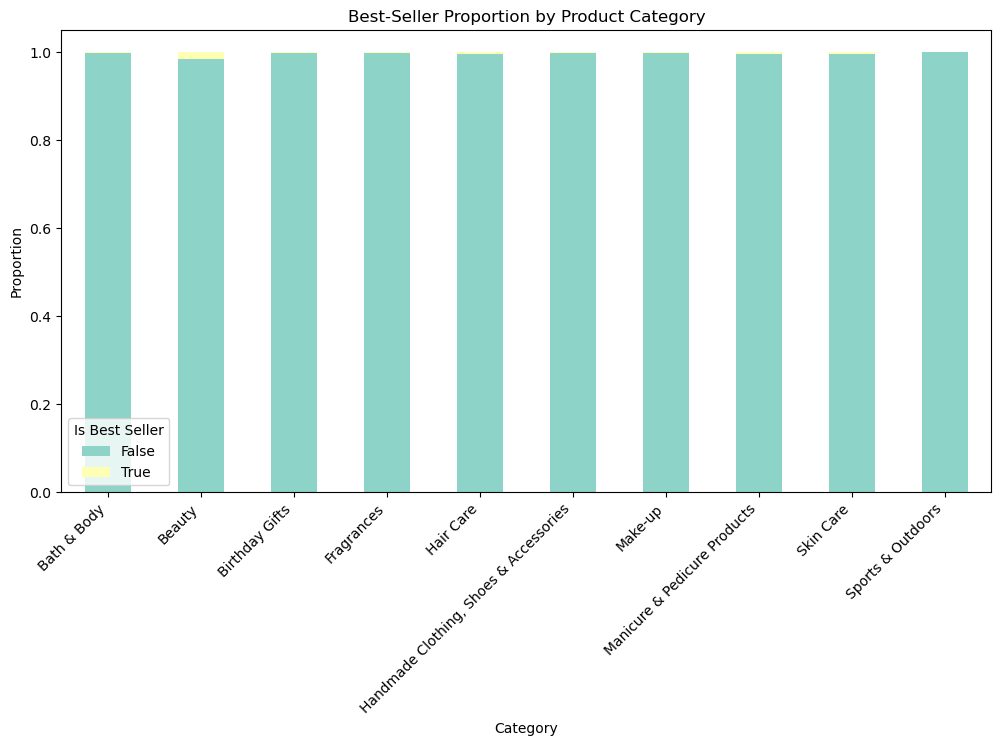

In [16]:
top_10_categories = df['category'].value_counts().head(10).index

df_top_categories = df[df['category'].isin(top_10_categories)]

stacked_data = pd.crosstab(
    df_top_categories['category'],
    df_top_categories['isBestSeller'],
    normalize='index'
)

stacked_data.plot(
    kind='bar',
    stacked=True,
    figsize=(12,6),
    color=sns.color_palette("Set3")[0:2]
)

plt.title('Best-Seller Proportion by Product Category')
plt.xlabel('Category')
plt.ylabel('Proportion')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Is Best Seller')

plt.show()

The stacked bar chart shows that non-best-seller products overwhelmingly dominate every top product category.

Best-seller products represent only a very small proportion of listings across all categories. However, slight differences can still be observed between categories, which aligns with the statistical results obtained from the Chi-square test and Cramér’s V.

Overall, the visualization suggests that becoming a best-seller is relatively uncommon regardless of category, although some categories show marginally higher best-seller proportions.

### Final insight

Overall, the product category has a statistically significant but weak relationship with best-seller status.

Certain categories, such as Grocery and Health & Personal Care, exhibit higher proportions of best-seller products, suggesting that category-specific demand patterns may influence marketplace performance.

However, the weak Cramér’s V value indicates that the category alone is not a strong predictor of best-seller success, and additional factors likely play important roles.

## Part 2: Exploring Product Prices and Ratings Across Categories and Brands

### Investigate how different product categories influence product prices.

#### Remove outliers in product prices

In [17]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Q1: 9.99
Q3: 45.99
IQR: 36.0
Lower bound: -44.01
Upper bound: 99.99000000000001


In [18]:
df_no_outliers = df[
    (df['price'] >= lower_bound) &
    (df['price'] <= upper_bound)
]

In [19]:
print("Original shape:", df.shape)
print("Shape without price outliers:", df_no_outliers.shape)
print("Rows removed:", df.shape[0] - df_no_outliers.shape[0])

Original shape: (2443651, 8)
Shape without price outliers: (2115963, 8)
Rows removed: 327688


In [20]:
df_no_outliers['price'].describe()

count    2.115963e+06
mean     2.340827e+01
std      2.051335e+01
min      0.000000e+00
25%      9.130000e+00
50%      1.599000e+01
75%      2.999000e+01
max      9.999000e+01
Name: price, dtype: float64

Using the IQR method, products with prices below Q1 - 1.5 * IQR or above Q3 + 1.5 * IQR were considered outliers and removed.

This step helps reduce the impact of extreme price values, making category-level price comparisons more reliable and easier to visualize.

## Violin Plots

In [21]:
top_20_categories = (
    df_no_outliers['category']
    .value_counts()
    .head(20)
    .index
)

In [22]:
df_top_20 = df_no_outliers[
    df_no_outliers['category'].isin(top_20_categories)
]

/var/folders/6y/g3t2k_6s01x98hz602dv0npw0000gn/T/ipykernel_23352/1639251631.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


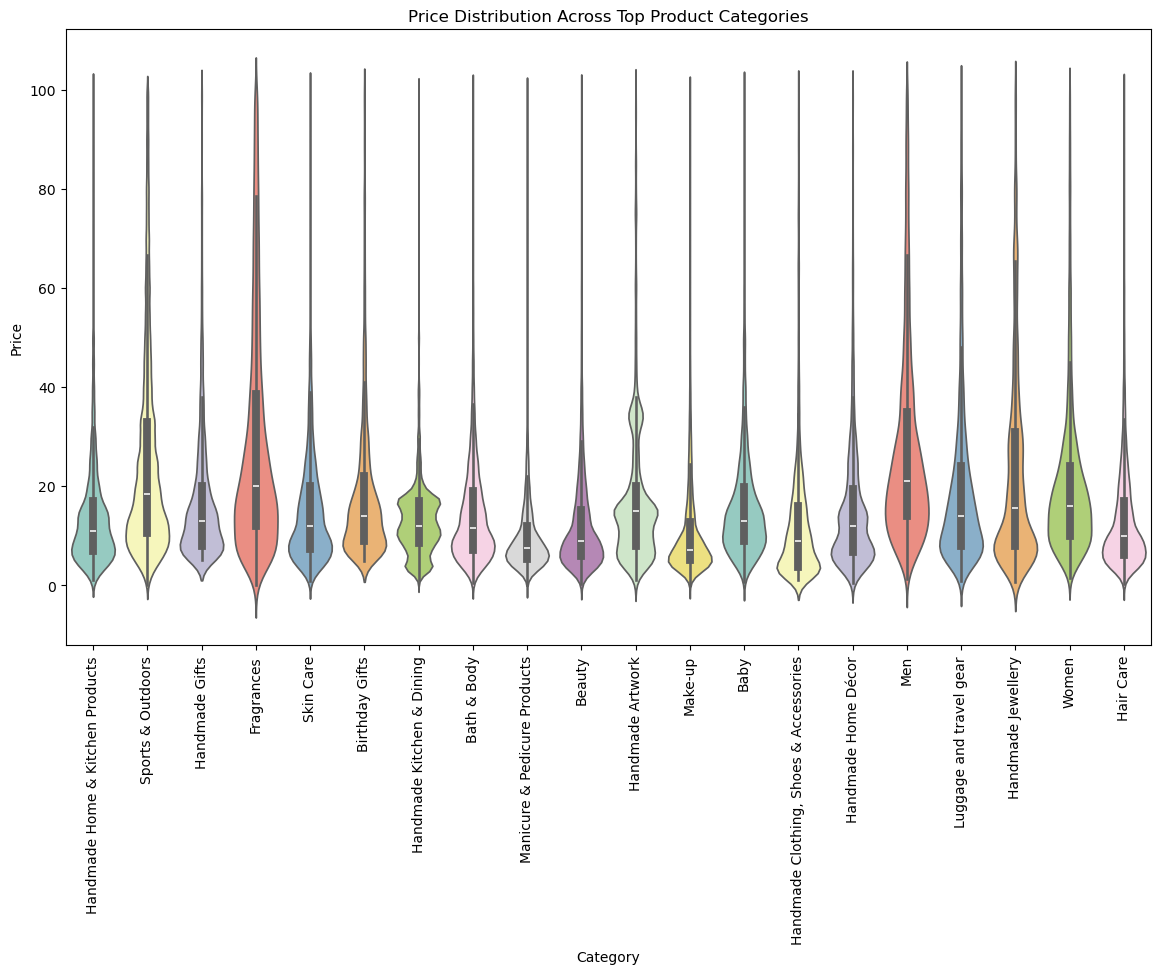

In [23]:
plt.figure(figsize=(14,8))

sns.violinplot(
    data=df_top_20,
    x='category',
    y='price',
    palette='Set3'
)

plt.title('Price Distribution Across Top Product Categories')
plt.xlabel('Category')
plt.ylabel('Price')

plt.xticks(rotation=90)

plt.show()

The violin plot reveals noticeable differences in price distributions across product categories.

Categories such as Men, Fragrances, Handmade Jewellery, and Women tend to display wider price distributions and higher median prices, indicating the presence of more premium-priced products.

In contrast, categories such as Beauty, Make-up, and Hair Care show narrower distributions concentrated around lower price ranges, suggesting that products in these categories are generally more affordable.

The varying shapes and widths of the violins also indicate that some categories have greater price variability than others.

### Which product category tends to have the highest median price?

## Median price per category

In [24]:
category_median_price = (
    df_no_outliers
    .groupby('category')['price']
    .median()
    .sort_values(ascending=False)
)

category_median_price.head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

The median price analysis shows that categories such as Desktop PCs, Boxing Shoes, Tablets, and Graphics Cards tend to have the highest typical product prices.

This indicates that technology-related and specialized sports categories generally command higher market prices compared with other product categories.

## Bar Charts

#### Average price by category

In [25]:
top_10_categories = (
    df_no_outliers['category']
    .value_counts()
    .head(10)
    .index
)

In [26]:
df_top_10 = df_no_outliers[
    df_no_outliers['category'].isin(top_10_categories)
]

In [27]:
average_price_by_category = (
    df_top_10
    .groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)

average_price_by_category

category
Sports & Outdoors                         25.172065
Birthday Gifts                            18.600195
Handmade Gifts                            17.395112
Skin Care                                 15.654722
Bath & Body                               14.678683
Hair Care                                 13.461408
Handmade Clothing, Shoes & Accessories    12.958639
Beauty                                    12.523480
Make-up                                   10.612918
Manicure & Pedicure Products              10.231825
Name: price, dtype: float64

#### Bar charts

/var/folders/6y/g3t2k_6s01x98hz602dv0npw0000gn/T/ipykernel_23352/1360485205.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


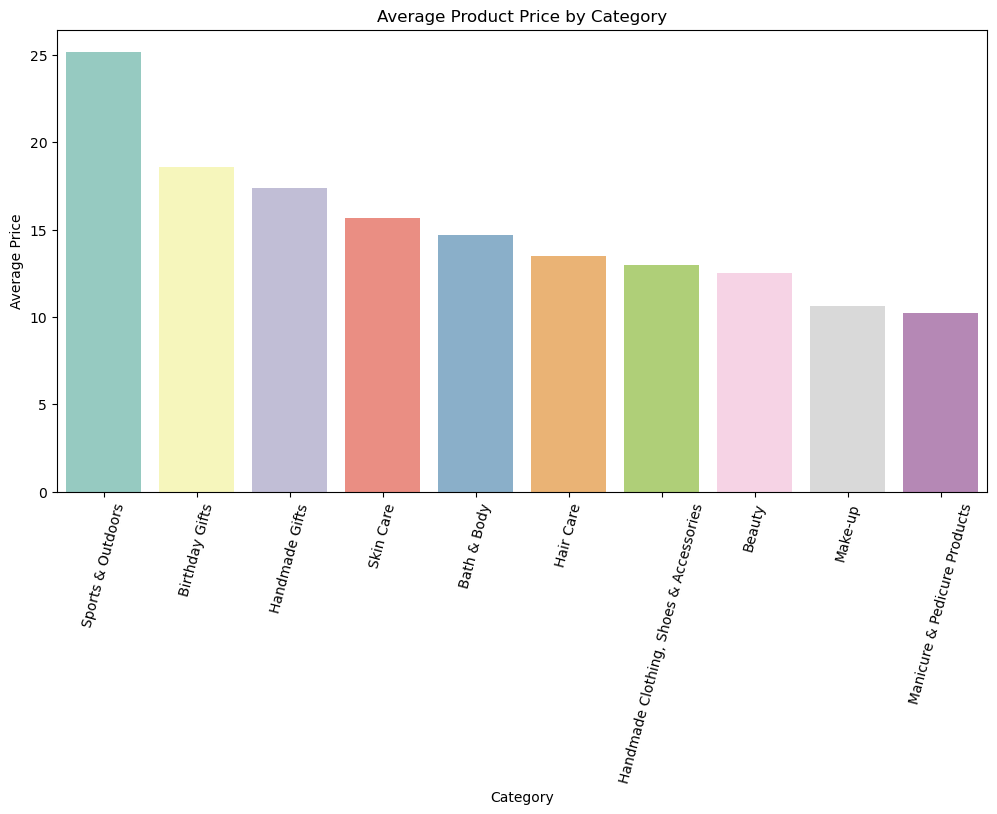

In [28]:
plt.figure(figsize=(12,6))

sns.barplot(
    x=average_price_by_category.index,
    y=average_price_by_category.values,
    palette='Set3'
)

plt.title('Average Product Price by Category')
plt.xlabel('Category')
plt.ylabel('Average Price')

plt.xticks(rotation=75)

plt.show()

The bar chart shows that, among the top 10 most frequent categories, Sports & Outdoors has the highest average product price.

Birthday Gifts and Handmade Gifts also show relatively high average prices compared with beauty-related categories such as Make-up and Manicure & Pedicure Products.

This suggests that, within the most common categories, Sports & Outdoors tends to command higher prices, while personal care and beauty subcategories are generally positioned at lower average price points.

## Box Plots

In [29]:
top_10_categories = (
    df_no_outliers['category']
    .value_counts()
    .head(10)
    .index
)

In [30]:
df_top_10 = df_no_outliers[
    df_no_outliers['category'].isin(top_10_categories)
]

/var/folders/6y/g3t2k_6s01x98hz602dv0npw0000gn/T/ipykernel_23352/12997383.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


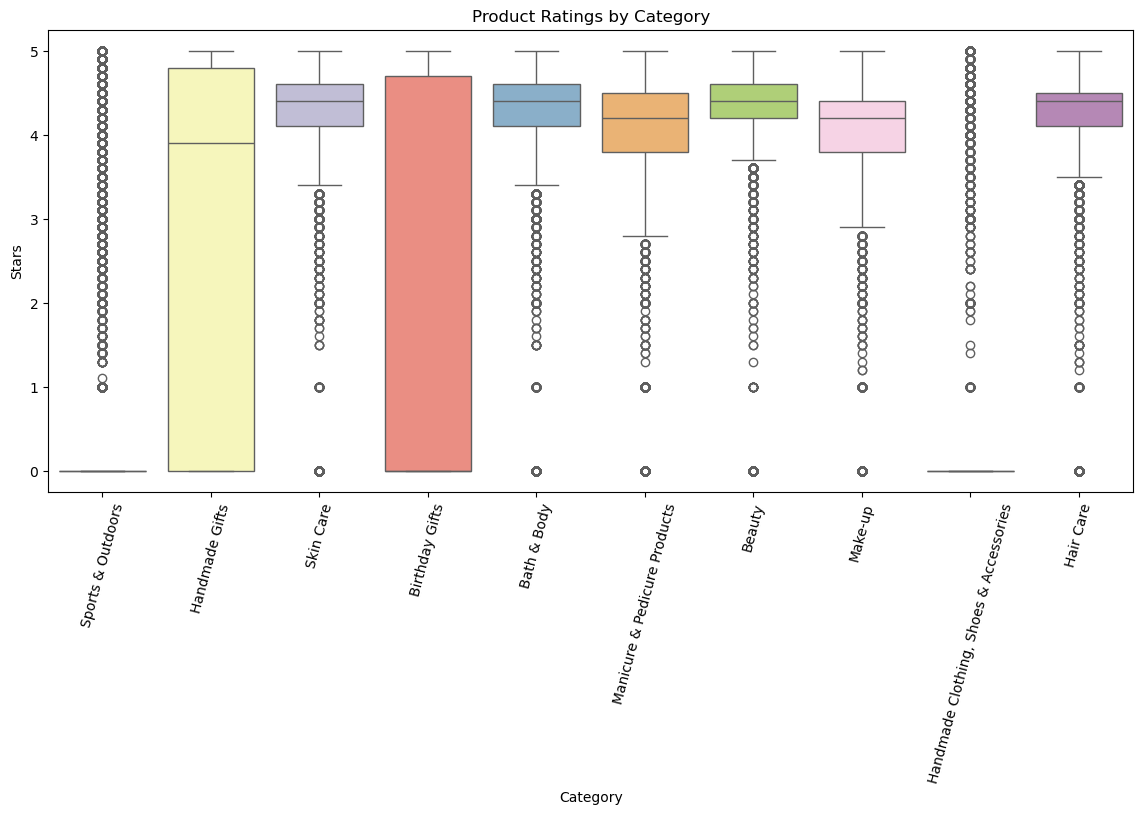

In [31]:
plt.figure(figsize=(14,6))

sns.boxplot(
    data=df_top_10,
    x='category',
    y='stars',
    palette='Set3'
)

plt.title('Product Ratings by Category')
plt.xlabel('Category')
plt.ylabel('Stars')

plt.xticks(rotation=75)

plt.show()

The boxplot shows that most categories have median ratings around 4.5 stars, indicating generally positive customer feedback.

Categories such as Skin Care, Bath & Body, Beauty, and Hair Care show relatively high median ratings and compact distributions, suggesting consistently favorable reviews.

Sports & Outdoors and Handmade Clothing, Shoes & Accessories show many ratings concentrated at 0, which may indicate unrated products or missing rating information encoded as zero.

Overall, customer ratings tend to be high across most top categories, but some categories show wider variability due to low or zero-star values.

### Median rating by category

In [32]:
category_median_rating = (
    df_no_outliers
    .groupby('category')['stars']
    .median()
    .sort_values(ascending=False)
)

category_median_rating.head(10)

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Hobbies                         4.6
Beer, Wine & Spirits            4.6
Laptop Accessories              4.6
Cables & Accessories            4.5
CPUs                            4.5
Name: stars, dtype: float64

The median rating analysis shows that most product categories have very high customer ratings, generally between 4.5 and 4.7 stars.

Computer Memory has the highest median rating at 4.7 stars, while categories such as Building & Construction Toys, Office Paper Products, Luxury Food & Drink, and Hobbies also show consistently high median ratings around 4.6 stars.

These results suggest that customers tend to provide very positive feedback across many Amazon UK product categories, especially for technology accessories, hobby-related products, and premium consumer goods.

High median ratings across multiple categories may indicate strong customer satisfaction within the Amazon UK marketplace.

Categories with especially high ratings could reflect higher product quality, better customer expectations alignment, or stronger brand reliability.

# Part 3: Investigating the Interplay Between Product Prices and Ratings

## Correlation Coefficients

In [33]:
correlation = df_no_outliers['price'].corr(df_no_outliers['stars'])

print("Correlation between price and stars:", correlation)

Correlation between price and stars: -0.0776729987818131


There is an extremely weak negative correlation between product price and product ratings.

This suggests that more expensive products do not necessarily receive better customer ratings.

## Visualizations

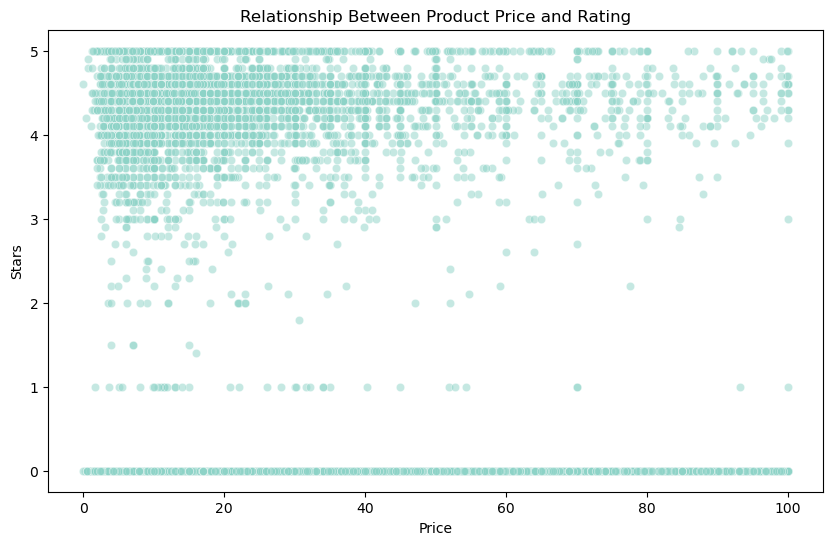

In [34]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df_no_outliers.sample(10000),
    x='price',
    y='stars',
    alpha=0.5,
    color=sns.color_palette("Set3")[0]
)

plt.title('Relationship Between Product Price and Rating')
plt.xlabel('Price')
plt.ylabel('Stars')

plt.show()

The scatter plot confirms the weak correlation observed previously.

Product ratings remain relatively high across all price ranges, indicating that price is not a strong predictor of customer satisfaction.

#### Correlation heatmap

In [35]:
numerical_df = df_no_outliers[
    ['stars', 'reviews', 'price', 'boughtInLastMonth']
]

In [36]:
correlation_matrix = numerical_df.corr()

correlation_matrix

,stars,reviews,price,boughtInLastMonth
stars,1.000000,0.083920,-0.077673,0.113994
reviews,0.083920,1.000000,-0.008498,0.105624
price,-0.077673,-0.008498,1.000000,-0.059051
boughtInLastMonth,0.113994,0.105624,-0.059051,1.000000


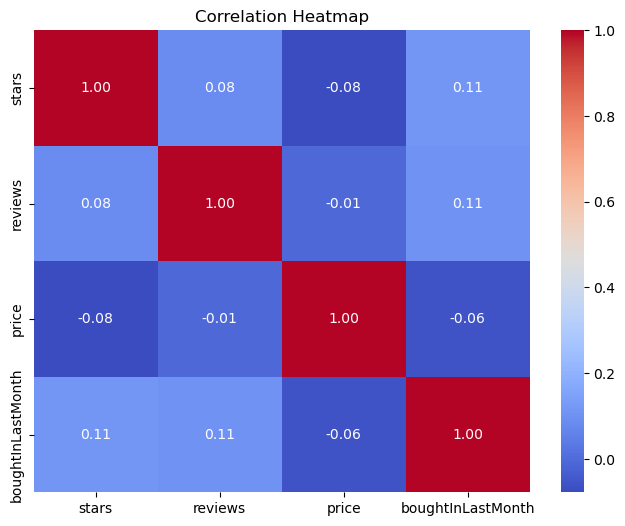

In [37]:
plt.figure(figsize=(8,6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

The heatmap reveals that most numerical variables exhibit weak correlations with one another.

This indicates that product pricing, ratings, reviews, and recent purchases behave relatively independently in the dataset.

#### QQ plot

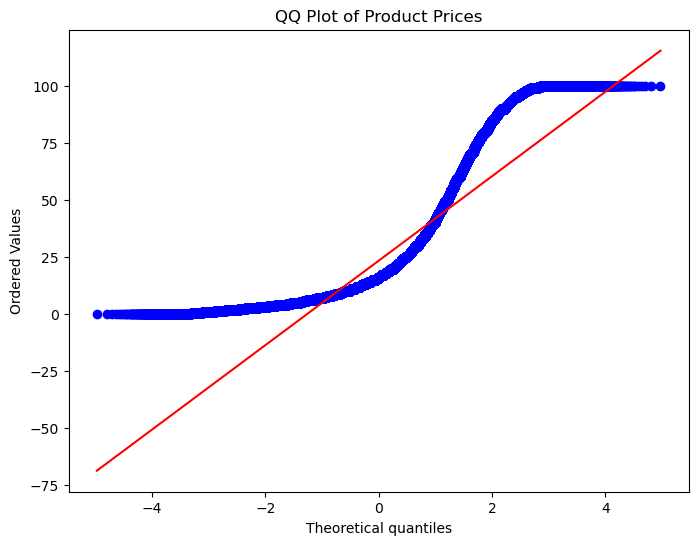

In [38]:
plt.figure(figsize=(8,6))

probplot(df_no_outliers['price'], dist="norm", plot=plt)

plt.title('QQ Plot of Product Prices')

plt.show()

The QQ plot shows strong deviations from the reference line, indicating that product prices are not normally distributed.

Prices are heavily right-skewed, with many low-priced products and a smaller number of relatively expensive products.

The analysis suggests that product prices and customer ratings are only weakly related.

Most products receive relatively high ratings regardless of price level, while pricing distributions remain highly skewed even after removing extreme outliers.

Additionally, the correlation analysis indicates that numerical variables such as price, reviews, ratings, and recent purchases are largely independent from one another.